<a href="https://colab.research.google.com/github/koliraj7580-debug/ML-Practical_01/blob/main/Practical_07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*   Student Name : Koli Raj Mohan
*   Div : A
*   Practical Batch : A2
*   Roll No : 58
*   Date : 27/10/2026
*   Practical No : 07
*   Practical Name : Apply K-Means and visualize clusters. Use silhouette score and elbow method to tune K.


1. Data Loading

In [1]:
# import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.figsize'] = (6, 5)  # Default fig size
plt.rcParams['figure.dpi'] = 150  # Default fig resolution
sns.set_style('darkgrid')  # Default diagram theme

In [2]:
df = pd.read_csv("/content/Mall_Customers.csv")
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


2. Exploratory Data Analysis & Visualization

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [4]:
# Drop the unnecessary columns
df.drop(['CustomerID', 'Gender', 'Age'], axis=1, inplace=True)
df.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


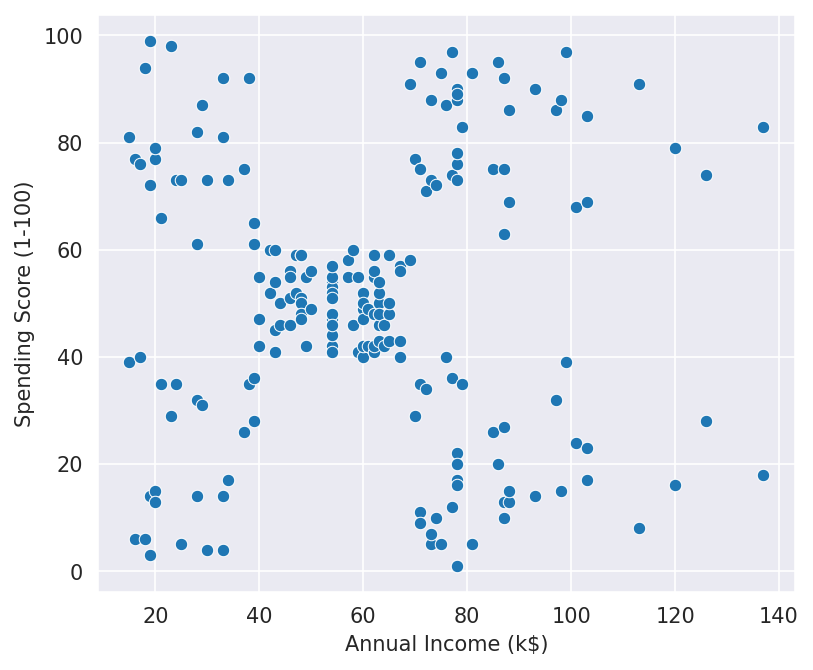

In [5]:
# Data visualization
sns.scatterplot(
    x=df['Annual Income (k$)'], y=df['Spending Score (1-100)'])
plt.show()

3. Data Preprocessing

In [6]:
# Standardization
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

x = sc.fit_transform(df)
x[:10]

array([[-1.73899919, -0.43480148],
       [-1.73899919,  1.19570407],
       [-1.70082976, -1.71591298],
       [-1.70082976,  1.04041783],
       [-1.66266033, -0.39597992],
       [-1.66266033,  1.00159627],
       [-1.62449091, -1.71591298],
       [-1.62449091,  1.70038436],
       [-1.58632148, -1.83237767],
       [-1.58632148,  0.84631002]])

4. Model Development (K-Means Clustering)

In [7]:
from sklearn.cluster import KMeans

km = KMeans()  # default 8 Cluster
yp = km.fit_predict(x)
yp

array([6, 5, 3, 5, 6, 5, 3, 5, 3, 5, 3, 5, 3, 5, 3, 5, 6, 5, 6, 5, 6, 5,
       3, 5, 3, 5, 6, 5, 6, 5, 3, 5, 3, 5, 3, 5, 3, 5, 6, 5, 6, 5, 6, 0,
       6, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 4, 0, 0, 4, 4, 0, 0, 0, 0,
       0, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4,
       4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 2, 4, 2, 4, 2, 1, 2, 1, 2,
       4, 2, 1, 2, 1, 2, 1, 2, 1, 2, 4, 2, 1, 2, 4, 2, 1, 2, 1, 2, 1, 2,
       1, 2, 1, 2, 1, 2, 4, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2,
       1, 2, 1, 7, 1, 7, 1, 7, 1, 7, 1, 7, 1, 7, 1, 7, 1, 7, 1, 7, 1, 7,
       1, 7], dtype=int32)

In [8]:
len(yp)

200

In [9]:
# cluster centre
km.cluster_centers_

array([[-0.49031358,  0.07634907],
       [ 1.1010449 , -1.34346864],
       [ 0.66703804,  1.23036618],
       [-1.37320883, -1.57680239],
       [ 0.1206509 , -0.15673077],
       [-1.35366972,  1.15873115],
       [-1.23585672, -0.65714315],
       [ 1.81769762,  1.26275949]])

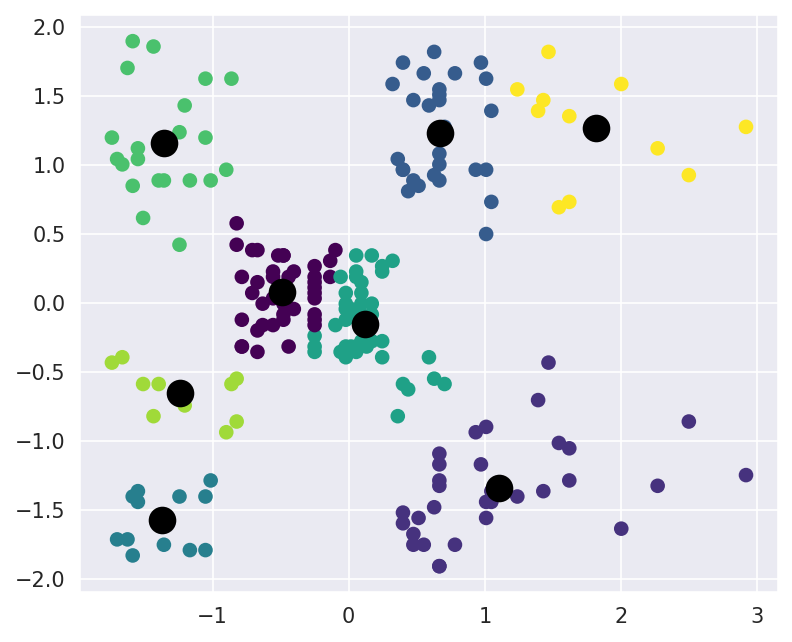

In [10]:
# Visualize the clusters- Scatter plot With Centroid of Each Cluster
plt.scatter(x[:, 0], x[:, 1], c=yp, cmap='viridis')
plt.scatter(
    km.cluster_centers_[:, 0],
    km.cluster_centers_[:, 1],
    c='black',
    s=150,  # C - Centroid Colour, S - Size of Centroid 100 to 200 range
)
plt.show()

In [11]:
km.inertia_  # - sum of squared distances of each sample to its nearest

42.004276238393075

Elbow Graph / Elbow Curve

*Elbow curve is the plot between K values and wcss




In [12]:
# WCSS (Within-Cluster Sum of Squares)
wcss = []

for i in range(1, 20):
  km = KMeans(n_clusters=i)
  km.fit_predict(x)
  wcss.append(km.inertia_)

In [13]:
wcss

[399.99999999999994,
 269.08518232778204,
 157.70400815035939,
 141.23723313452112,
 65.56840815571681,
 57.38174746022787,
 45.33255486071676,
 50.79829121580393,
 32.406659676456606,
 30.163961897377867,
 28.104208055665854,
 27.78663515484676,
 23.260329080181418,
 20.201813725725202,
 17.784934486103193,
 17.548387122834708,
 15.784529801684394,
 14.634583163894755,
 13.711640720084414]

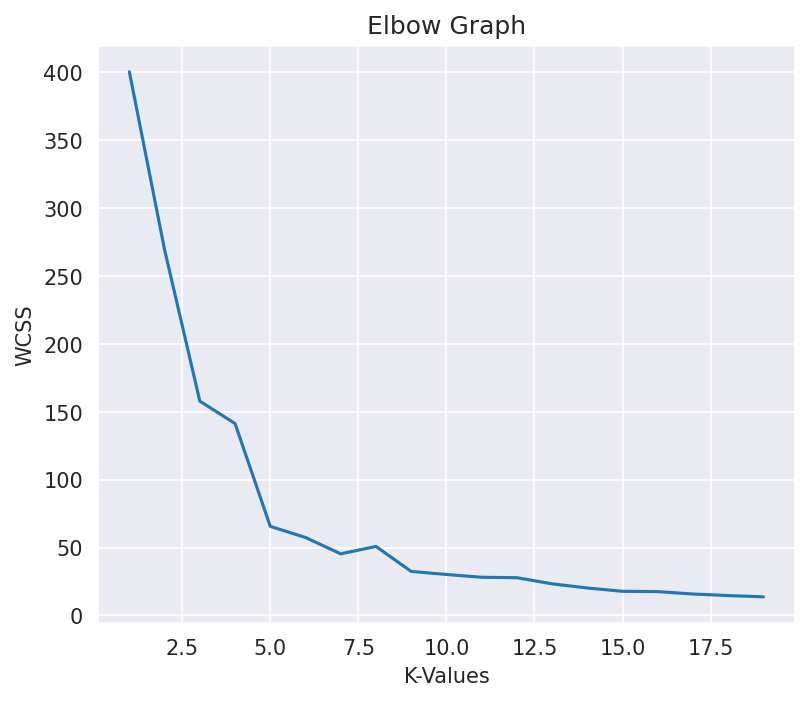

In [14]:
plt.plot(range(1, 20), wcss)
plt.xlabel('K-Values')
plt.ylabel('WCSS')
plt.title('Elbow Graph')
plt.show()

5. Model Evaluation & Optimal K Selection

In [15]:
from sklearn.metrics import silhouette_score

silhouette_score(x, yp)

np.float64(0.4549690690947958)

Optimal K Determination & Final K-Means Model

K = 2, Silhouette Score = 0.321
K = 3, Silhouette Score = 0.467
K = 4, Silhouette Score = 0.494
K = 5, Silhouette Score = 0.555
K = 6, Silhouette Score = 0.540
K = 7, Silhouette Score = 0.528
K = 8, Silhouette Score = 0.455
K = 9, Silhouette Score = 0.457
K = 10, Silhouette Score = 0.443


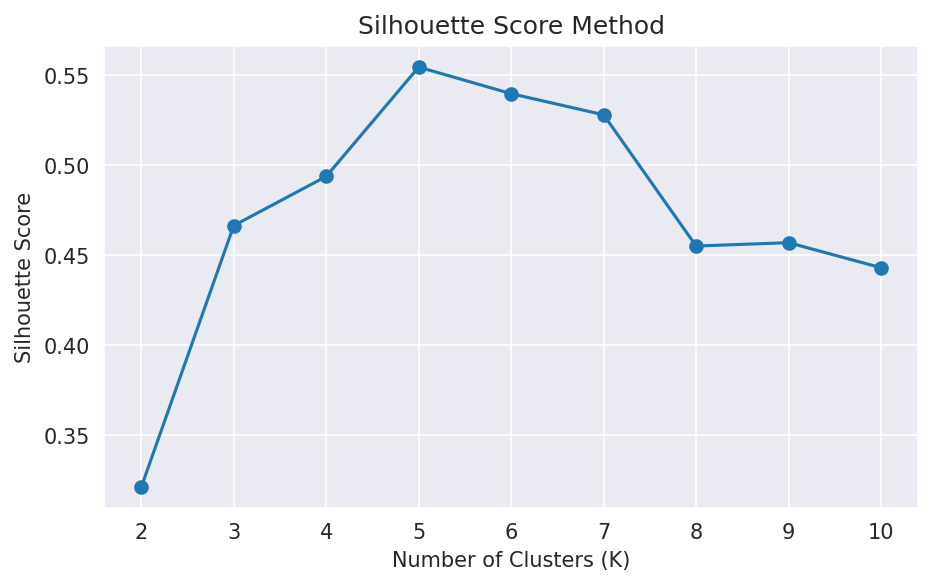

In [16]:
# Step 5: Silhouette Score Analysis
silhouette_scores = []

for k in range(2, 11):
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  labels = kmeans.fit_predict(x)
  score = silhouette_score(x, labels)
  silhouette_scores.append(score)
  print(f'K = {k}, Silhouette Score = {score:.3f}')

# Visualize Silhouette Scores
plt.figure(figsize=(7, 4))
plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.title('Silhouette Score Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()